In [7]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import TimestampType
from IPython.display import display
import matplotlib.pyplot as plt

spark = (SparkSession.builder
    .appName("partB")
    .config("spark.driver.memory", "8g")
    .getOrCreate())

csv_path = "yellow_tripdata_2015-01.csv"

In [8]:
df = spark.read.csv(csv_path, header=True, inferSchema=True)

trips = (df
    .dropna(subset=["fare_amount", "trip_distance", "passenger_count"])
    .filter((F.col("fare_amount") > 0) & (F.col("trip_distance") > 0))
    .withColumn("pickup_time", F.col("tpep_pickup_datetime").cast(TimestampType()))
    .withColumn("dropoff_time", F.col("tpep_dropoff_datetime").cast(TimestampType()))
    .filter((F.col("pickup_time") >= "2015-01-01") & (F.col("pickup_time") < "2015-02-01"))
)

In [9]:
trips = (trips
    .withColumn(
        "trip_duration",
        (F.unix_timestamp("dropoff_time") - F.unix_timestamp("pickup_time")) / 60.0
    )
    .filter(F.col("trip_duration") > 0)
)

display(trips.select("pickup_time", "dropoff_time", "trip_duration").limit(10).toPandas())

C:\Users\georg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,pickup_time,dropoff_time,trip_duration
0,2015-01-15 19:05:39,2015-01-15 19:23:42,18.050000
1,2015-01-10 20:33:38,2015-01-10 20:53:28,19.833333
2,2015-01-10 20:33:38,2015-01-10 20:43:41,10.050000
3,2015-01-10 20:33:39,2015-01-10 20:35:31,1.866667
4,2015-01-10 20:33:39,2015-01-10 20:52:58,19.316667
5,2015-01-10 20:33:39,2015-01-10 20:53:52,20.216667
6,2015-01-10 20:33:39,2015-01-10 20:58:31,24.866667
7,2015-01-10 20:33:39,2015-01-10 20:42:20,8.683333
8,2015-01-10 20:33:39,2015-01-10 21:11:35,37.933333
9,2015-01-10 20:33:40,2015-01-10 20:40:44,7.066667


In [10]:
trips = (trips
    .withColumn("hour_of_day", F.hour("pickup_time"))
    .withColumn("day_of_week", ((F.dayofweek("pickup_time") + 5) % 7) + 1)
    .withColumn("day_name", F.date_format("pickup_time", "EEEE"))
)

display(trips.select("pickup_time", "hour_of_day", "day_of_week", "day_name").limit(10).toPandas())

C:\Users\georg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,pickup_time,hour_of_day,day_of_week,day_name
0,2015-01-15 19:05:39,19,4,Thursday
1,2015-01-10 20:33:38,20,6,Saturday
2,2015-01-10 20:33:38,20,6,Saturday
3,2015-01-10 20:33:39,20,6,Saturday
4,2015-01-10 20:33:39,20,6,Saturday
5,2015-01-10 20:33:39,20,6,Saturday
6,2015-01-10 20:33:39,20,6,Saturday
7,2015-01-10 20:33:39,20,6,Saturday
8,2015-01-10 20:33:39,20,6,Saturday
9,2015-01-10 20:33:40,20,6,Saturday


DataFrame[week: int, total_trips: bigint, avg_duration: double, total_revenue: double]

C:\Users\georg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


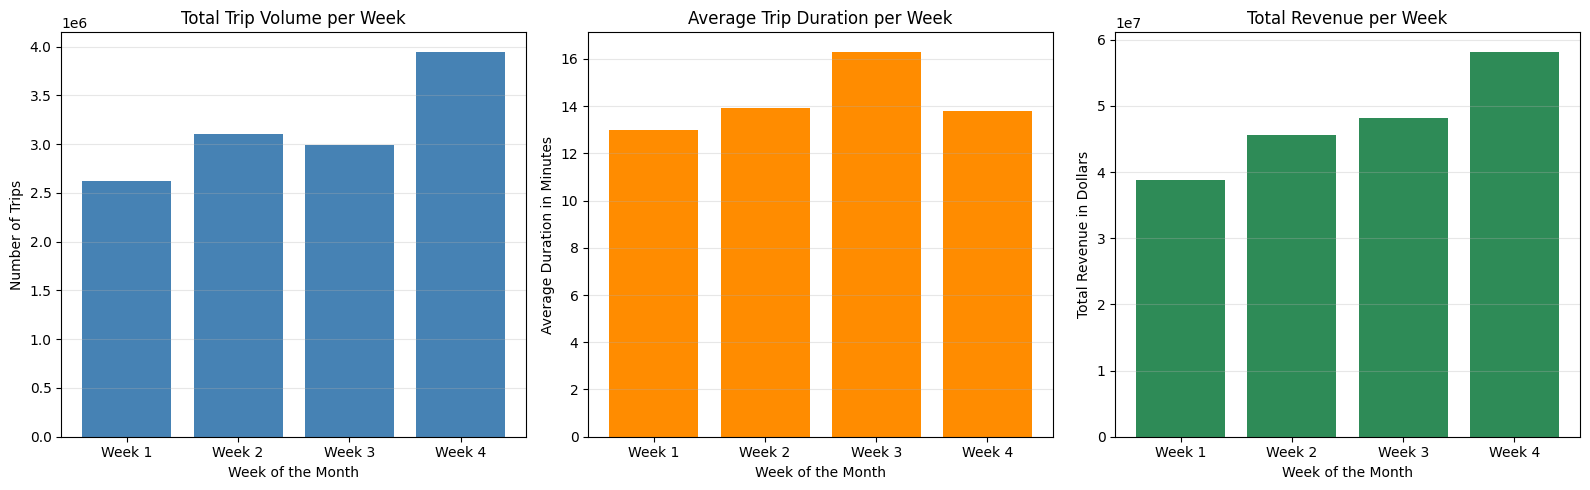

In [11]:
trips = trips.withColumn(
    "week",
    F.least(F.ceil(F.dayofmonth("pickup_time") / 7), F.lit(4)).cast("int")
)

weekly = (trips.groupBy("week")
    .agg(
        F.count("*").alias("total_trips"),
        F.round(F.avg("trip_duration"), 2).alias("avg_duration"),
        F.round(F.sum("total_amount"), 2).alias("total_revenue")
    )
    .orderBy("week"))

display(weekly)

weekly_pd = weekly.toPandas()
week_labels = ["Week " + str(w) for w in weekly_pd["week"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plots = [
    (axes[0], "total_trips", "steelblue", "Total Trip Volume per Week", "Number of Trips"),
    (axes[1], "avg_duration", "darkorange", "Average Trip Duration per Week", "Average Duration in Minutes"),
    (axes[2], "total_revenue", "seagreen", "Total Revenue per Week", "Total Revenue in Dollars"),
]

for ax, column, color, title, label in plots:
    ax.bar(week_labels, weekly_pd[column], color=color)
    ax.set_title(title)
    ax.set_xlabel("Week of the Month")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

DataFrame[hour_of_day: int, avg_duration: double]

C:\Users\georg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


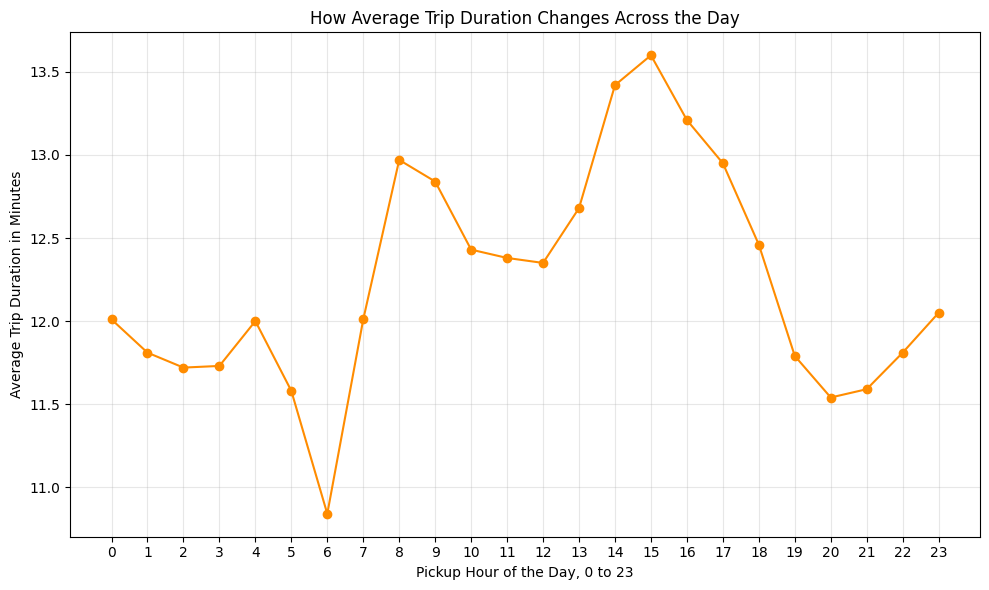

In [12]:
hourly = (trips
    .filter(F.col("trip_duration") < 180)
    .groupBy("hour_of_day")
    .agg(F.round(F.avg("trip_duration"), 2).alias("avg_duration"))
    .orderBy("hour_of_day"))

display(hourly)

hourly_pd = hourly.toPandas()
plt.figure(figsize=(10, 6))
plt.plot(hourly_pd["hour_of_day"], hourly_pd["avg_duration"], marker="o", color="darkorange")
plt.xlabel("Pickup Hour of the Day 0 to 23")
plt.ylabel("Average Trip Duration in Minutes")
plt.title("How Average Trip Duration Changes Across the Day")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()